# AMI Whole-Meeting Preprocessing Pipeline

This notebook replaces the old utterance-level AMI preprocessing workflow.

## Workflow

AMI whole-meeting dataset
→ select whole meetings
→ split at meeting level
→ save raw WAV files
→ save ground-truth speaker transcripts
→ preprocess audio
→ verify audio and reference alignment

### Dataset

This notebook uses `Trelis/tiron-eval-meetings`, AMI split.

The selected AMI rows are whole-meeting recordings with speaker-attributed reference utterances.

Selected meetings:

- ES2004a
- IS1009a
- TS3003a
- EN2002a

The recordings are multi-minute meeting files instead of the short utterance-level rows used in the old project.

## 1. Install required libraries

This cell uses the current notebook Python interpreter so the packages are installed into the same environment as the kernel.

Run it once.

In [30]:
%pip -q install datasets huggingface_hub librosa soundfile numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [31]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt

from datasets import load_dataset, Audio

## 3. Project configuration

The split is performed at the **meeting level**.

No portion of the same meeting is placed in both train and test.

In [32]:
from pathlib import Path

BASE_DIR = Path.cwd()

# Existing project structure is preserved.
DATASET_DIR = BASE_DIR / "dataset"
RAW_DIR = DATASET_DIR / "raw"
PROCESSED_DIR = DATASET_DIR / "processed"
REFERENCE_DIR = DATASET_DIR / "references"

for split in ["train", "test"]:
    (RAW_DIR / split).mkdir(parents=True, exist_ok=True)
    (PROCESSED_DIR / split).mkdir(parents=True, exist_ok=True)
    (REFERENCE_DIR / split).mkdir(parents=True, exist_ok=True)

# Whole-meeting split.
TRAIN_MEETINGS = ["ES2004a", "IS1009a"]
TEST_MEETINGS = ["TS3003a", "EN2002a"]

ALL_MEETINGS = TRAIN_MEETINGS + TEST_MEETINGS

print("Project directory :", BASE_DIR)
print("Train meetings    :", TRAIN_MEETINGS)
print("Test meetings     :", TEST_MEETINGS)

Project directory : /Users/manish/Documents/KU/SEM 5/DL/DL
Train meetings    : ['ES2004a', 'IS1009a']
Test meetings     : ['TS3003a', 'EN2002a']


## 4. Load the whole-meeting AMI dataset

Audio decoding is disabled so the stored WAV bytes can be written directly to the raw-data folder.

The `utterances_json` field is kept as the machine-readable ground-truth transcript.

In [33]:
import os
from dotenv import load_dotenv
from huggingface_hub import login

load_dotenv()

HF_TOKEN = os.getenv("HF_TOKEN")

if HF_TOKEN:
    login(token=HF_TOKEN)
    print("Hugging Face authentication successful.")
else:
    print("HF_TOKEN not found. Continuing without authentication.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face authentication successful.


In [34]:
DATASET_NAME = "Trelis/tiron-eval-meetings"
DATASET_SPLIT = "ami"

print("Loading:", DATASET_NAME)
ds = load_dataset(DATASET_NAME, split=DATASET_SPLIT)

# Do not automatically decode audio.
ds = ds.cast_column("audio", Audio(decode=False))

print(ds)
print("\nColumns:")
print(ds.column_names)

Loading: Trelis/tiron-eval-meetings
Dataset({
    features: ['corpus', 'meeting_id', 'audio', 'utterances_json', 'unknown_spans_json', 'duration_s'],
    num_rows: 4
})

Columns:
['corpus', 'meeting_id', 'audio', 'utterances_json', 'unknown_spans_json', 'duration_s']


## 5. Inspect the available meetings

This confirms that the selected dataset contains whole meetings and shows their durations and reference sizes.

In [35]:
rows = []

for row in ds:
    meeting_id = row["meeting_id"]
    duration_s = float(row["duration_s"])

    utterances = json.loads(row["utterances_json"])
    speakers = sorted({u["speaker_id"] for u in utterances})

    rows.append({
        "meeting_id": meeting_id,
        "duration_s": duration_s,
        "duration_min": duration_s / 60.0,
        "num_utterances": len(utterances),
        "num_speakers": len(speakers),
        "speakers": ", ".join(speakers),
    })

meeting_df = (
    pd.DataFrame(rows)
    .sort_values("meeting_id")
    .reset_index(drop=True)
)

display(meeting_df)

print("\nTotal meetings:", len(meeting_df))
print("Total duration (minutes):", round(meeting_df["duration_min"].sum(), 2))

,meeting_id,duration_s,duration_min,num_utterances,num_speakers,speakers
0,EN2002a,2142.709961,35.711833,746,4,"EN2002a.A, EN2002a.B, EN2002a.C, EN2002a.D"
1,ES2004a,1049.349976,17.489166,260,4,"ES2004a.A, ES2004a.B, ES2004a.C, ES2004a.D"
2,IS1009a,839.000000,13.983333,195,4,"IS1009a.A, IS1009a.B, IS1009a.C, IS1009a.D"
3,TS3003a,1505.640015,25.094000,242,4,"TS3003a.A, TS3003a.B, TS3003a.C, TS3003a.D"



Total meetings: 4
Total duration (minutes): 92.28


## 6. Validate the train/test split

Each selected meeting must exist exactly once, and each selected recording must be several minutes long.

In [36]:
available_meetings = set(meeting_df["meeting_id"])

missing_train = sorted(set(TRAIN_MEETINGS) - available_meetings)
missing_test = sorted(set(TEST_MEETINGS) - available_meetings)
duplicates = set(TRAIN_MEETINGS) & set(TEST_MEETINGS)

if missing_train:
    raise ValueError(f"Missing train meetings: {missing_train}")

if missing_test:
    raise ValueError(f"Missing test meetings: {missing_test}")

if duplicates:
    raise ValueError(f"Meetings appear in both train and test: {sorted(duplicates)}")

selected_df = meeting_df[meeting_df["meeting_id"].isin(ALL_MEETINGS)].copy()

short_meetings = selected_df[selected_df["duration_s"] < 5 * 60]

if not short_meetings.empty:
    raise ValueError(
        "At least one selected meeting is shorter than 5 minutes: "
        + ", ".join(short_meetings["meeting_id"].tolist())
    )

print("Split validation passed.")
print("Train:", TRAIN_MEETINGS)
print("Test :", TEST_MEETINGS)

Split validation passed.
Train: ['ES2004a', 'IS1009a']
Test : ['TS3003a', 'EN2002a']


## 7. Helper functions

The functions below:

- normalize reference utterances,
- build a structured reference JSON,
- save raw WAV bytes,
- save readable reference TXT,
- determine train/test membership.

In [37]:
def normalize_reference_utterance(utterance):
    return {
        "speaker": str(utterance["speaker_id"]),
        "start": float(utterance["begin_time"]),
        "end": float(utterance["end_time"]),
        "text": str(utterance["text"]).strip(),
    }


def build_reference(meeting_id, duration_s, utterances):
    normalized = [
        normalize_reference_utterance(u)
        for u in utterances
        if str(u.get("text", "")).strip()
    ]

    normalized.sort(key=lambda x: (x["start"], x["end"], x["speaker"]))

    speakers = sorted({u["speaker"] for u in normalized})

    return {
        "meeting_id": meeting_id,
        "language": "en-US",
        "duration_s": float(duration_s),
        "speakers": speakers,
        "num_speakers": len(speakers),
        "num_utterances": len(normalized),
        "segments": normalized,
    }


def save_reference_files(reference, split):
    meeting_id = reference["meeting_id"]

    json_path = REFERENCE_DIR / split / f"{meeting_id}.json"
    txt_path = REFERENCE_DIR / split / f"{meeting_id}.txt"

    with json_path.open("w", encoding="utf-8") as f:
        json.dump(reference, f, indent=2, ensure_ascii=False)

    with txt_path.open("w", encoding="utf-8") as f:
        for segment in reference["segments"]:
            f.write(
                f'[{segment["start"]:.2f}s - {segment["end"]:.2f}s] '
                f'{segment["speaker"]}: {segment["text"]}\n'
            )

    return json_path, txt_path


def save_audio_bytes(row, split):
    meeting_id = row["meeting_id"]
    audio_info = row["audio"]

    audio_bytes = audio_info.get("bytes")

    if audio_bytes is None:
        raise ValueError(
            f"No embedded audio bytes found for meeting {meeting_id}."
        )

    output_path = RAW_DIR / split / f"{meeting_id}.wav"

    with output_path.open("wb") as f:
        f.write(audio_bytes)

    return output_path


def get_split(meeting_id):
    if meeting_id in TRAIN_MEETINGS:
        return "train"
    if meeting_id in TEST_MEETINGS:
        return "test"
    raise ValueError(f"Meeting {meeting_id} is not configured.")

## 8. Save raw meetings and ground-truth references

For every meeting this creates:

```text
dataset/raw/<split>/<meeting_id>.wav
dataset/references/<split>/<meeting_id>.json
dataset/references/<split>/<meeting_id>.txt
```

The original raw audio is never overwritten during preprocessing.

In [38]:
metadata_rows = []

for row in ds:
    meeting_id = row["meeting_id"]

    if meeting_id not in ALL_MEETINGS:
        continue

    split = get_split(meeting_id)
    duration_s = float(row["duration_s"])
    utterances = json.loads(row["utterances_json"])

    reference = build_reference(
        meeting_id=meeting_id,
        duration_s=duration_s,
        utterances=utterances,
    )

    raw_audio_path = save_audio_bytes(row, split)
    reference_json_path, reference_txt_path = save_reference_files(
        reference,
        split,
    )

    metadata_rows.append({
        "meeting_id": meeting_id,
        "split": split,
        "duration_s": duration_s,
        "duration_min": duration_s / 60.0,
        "num_speakers": reference["num_speakers"],
        "num_utterances": reference["num_utterances"],
        "raw_audio": str(raw_audio_path),
        "reference_json": str(reference_json_path),
        "reference_txt": str(reference_txt_path),
    })

metadata_df = (
    pd.DataFrame(metadata_rows)
    .sort_values(["split", "meeting_id"])
    .reset_index(drop=True)
)

display(metadata_df)

,meeting_id,split,duration_s,duration_min,num_speakers,num_utterances,raw_audio,reference_json,reference_txt
0,EN2002a,test,2142.709961,35.711833,4,746,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...
1,TS3003a,test,1505.640015,25.094000,4,242,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...
2,ES2004a,train,1049.349976,17.489166,4,260,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...
3,IS1009a,train,839.000000,13.983333,4,195,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...


## 9. Verify raw WAV files

Checks:

- file exists,
- sample rate,
- number of channels,
- duration,
- file size.

The selected benchmark provides 16 kHz mono whole-meeting WAV audio.

In [39]:
raw_check_rows = []

for _, row in metadata_df.iterrows():
    path = Path(row["raw_audio"])

    if not path.exists():
        raise FileNotFoundError(path)

    audio, sr = librosa.load(
        path,
        sr=None,
        mono=False,
    )

    if audio.ndim == 1:
        channels = 1
        num_samples = len(audio)
    else:
        channels = audio.shape[0]
        num_samples = audio.shape[-1]

    duration = num_samples / sr

    raw_check_rows.append({
        "meeting_id": row["meeting_id"],
        "split": row["split"],
        "sample_rate": sr,
        "channels": channels,
        "duration_s": duration,
        "duration_min": duration / 60.0,
        "size_mb": path.stat().st_size / (1024 * 1024),
    })

raw_check_df = pd.DataFrame(raw_check_rows)
display(raw_check_df)

if not (raw_check_df["sample_rate"] == 16000).all():
    print("Warning: one or more raw files are not 16 kHz.")

if not (raw_check_df["channels"] == 1).all():
    print("Warning: one or more raw files are not mono.")

,meeting_id,split,sample_rate,channels,duration_s,duration_min,size_mb
0,EN2002a,test,16000,1,2142.709375,35.711823,65.390343
1,TS3003a,test,16000,1,1505.642625,25.094044,45.948608
2,ES2004a,train,16000,1,1049.354687,17.489245,32.023806
3,IS1009a,train,16000,1,838.997313,13.983289,25.604208


## 10. Audio preprocessing function

The preprocessing remains aligned with the original project:

1. load original audio,
2. convert to mono,
3. resample to 16 kHz,
4. peak-normalize,
5. save processed WAV.

This preserves the same overall workflow while changing only the dataset from short utterance clips to whole meetings.

In [40]:
TARGET_SR = 16000


def preprocess_audio(input_path, output_path, target_sr=TARGET_SR):
    audio, sr = librosa.load(
        input_path,
        sr=None,
        mono=False,
    )

    if audio.ndim > 1:
        audio = librosa.to_mono(audio)

    if sr != target_sr:
        audio = librosa.resample(
            audio,
            orig_sr=sr,
            target_sr=target_sr,
        )
        sr = target_sr

    max_value = np.max(np.abs(audio))

    if max_value > 0:
        audio = audio / max_value

    sf.write(
        output_path,
        audio.astype(np.float32),
        sr,
    )

## 11. Preprocess all selected meetings

Creates:

```text
dataset/processed/train/
dataset/processed/test/
```

There is one processed WAV per whole meeting.

In [41]:
for _, row in metadata_df.iterrows():
    split = row["split"]
    meeting_id = row["meeting_id"]

    input_path = Path(row["raw_audio"])
    output_path = PROCESSED_DIR / split / f"{meeting_id}.wav"

    preprocess_audio(input_path, output_path)

    print(f"Processed: {meeting_id} -> {output_path}")

print("\nAudio preprocessing completed.")

Processed: EN2002a -> /Users/manish/Documents/KU/SEM 5/DL/DL/dataset/processed/test/EN2002a.wav
Processed: TS3003a -> /Users/manish/Documents/KU/SEM 5/DL/DL/dataset/processed/test/TS3003a.wav
Processed: ES2004a -> /Users/manish/Documents/KU/SEM 5/DL/DL/dataset/processed/train/ES2004a.wav
Processed: IS1009a -> /Users/manish/Documents/KU/SEM 5/DL/DL/dataset/processed/train/IS1009a.wav

Audio preprocessing completed.


## 12. Verify processed audio

Every processed file must be:

- mono,
- 16 kHz,
- several minutes long.

Duration should remain close to the raw meeting duration.

In [42]:
processed_check_rows = []

for _, row in metadata_df.iterrows():
    split = row["split"]
    meeting_id = row["meeting_id"]

    path = PROCESSED_DIR / split / f"{meeting_id}.wav"

    if not path.exists():
        raise FileNotFoundError(path)

    audio, sr = librosa.load(
        path,
        sr=None,
        mono=False,
    )

    if audio.ndim != 1:
        raise ValueError(
            f"{meeting_id}: processed audio is not mono. Shape={audio.shape}"
        )

    duration = librosa.get_duration(y=audio, sr=sr)

    processed_check_rows.append({
        "meeting_id": meeting_id,
        "split": split,
        "sample_rate": sr,
        "channels": 1,
        "duration_s": duration,
        "duration_min": duration / 60.0,
        "size_mb": path.stat().st_size / (1024 * 1024),
    })

processed_df = pd.DataFrame(processed_check_rows)
display(processed_df)

if not (processed_df["sample_rate"] == TARGET_SR).all():
    raise ValueError("At least one processed file is not 16 kHz.")

if not (processed_df["channels"] == 1).all():
    raise ValueError("At least one processed file is not mono.")

,meeting_id,split,sample_rate,channels,duration_s,duration_min,size_mb
0,EN2002a,test,16000,1,2142.709375,35.711823,65.390343
1,TS3003a,test,16000,1,1505.642625,25.094044,45.948608
2,ES2004a,train,16000,1,1049.354687,17.489245,32.023806
3,IS1009a,train,16000,1,838.997313,13.983289,25.604208


## 13. Save the project metadata manifest

`dataset/metadata.csv` is the central mapping between:

- meeting ID,
- split,
- processed audio,
- raw audio,
- ground-truth transcript,
- duration,
- speaker count,
- utterance count.

The later Whisper, AssemblyAI, FLAN-T5 and BART notebooks can use this manifest instead of rebuilding file mappings.

In [43]:
manifest_rows = []

for _, row in metadata_df.iterrows():
    split = row["split"]
    meeting_id = row["meeting_id"]

    processed_path = PROCESSED_DIR / split / f"{meeting_id}.wav"

    manifest_rows.append({
        "meeting_id": meeting_id,
        "split": split,
        "duration_s": row["duration_s"],
        "duration_min": row["duration_min"],
        "num_speakers": row["num_speakers"],
        "num_utterances": row["num_utterances"],
        "raw_audio": row["raw_audio"],
        "processed_audio": str(processed_path),
        "reference_json": row["reference_json"],
        "reference_txt": row["reference_txt"],
    })

manifest_df = (
    pd.DataFrame(manifest_rows)
    .sort_values(["split", "meeting_id"])
    .reset_index(drop=True)
)

manifest_path = DATASET_DIR / "metadata.csv"
manifest_df.to_csv(manifest_path, index=False, encoding="utf-8")

print("Saved:", manifest_path)
display(manifest_df)

Saved: /Users/manish/Documents/KU/SEM 5/DL/DL/dataset/metadata.csv


,meeting_id,split,duration_s,duration_min,num_speakers,num_utterances,raw_audio,processed_audio,reference_json,reference_txt
0,EN2002a,test,2142.709961,35.711833,4,746,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...
1,TS3003a,test,1505.640015,25.094000,4,242,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...
2,ES2004a,train,1049.349976,17.489166,4,260,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...
3,IS1009a,train,839.000000,13.983333,4,195,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...,/Users/manish/Documents/KU/SEM 5/DL/DL/dataset...


## 14. Inspect one ground-truth transcript

The JSON reference is the ground truth used later for STT evaluation.

Speaker IDs are preserved from the source annotations.

In [44]:
sample_meeting = manifest_df.iloc[0]["meeting_id"]
sample_ref = Path(manifest_df.iloc[0]["reference_json"])

with sample_ref.open("r", encoding="utf-8") as f:
    reference = json.load(f)

print("Meeting:", sample_meeting)
print("Duration:", round(reference["duration_s"] / 60, 2), "minutes")
print("Speakers:", ", ".join(reference["speakers"]))
print("Utterances:", reference["num_utterances"])
print("\nFirst 10 reference segments:\n")

for segment in reference["segments"][:10]:
    print(
        f'[{segment["start"]:7.2f}s - {segment["end"]:7.2f}s] '
        f'{segment["speaker"]}: {segment["text"]}'
    )

Meeting: EN2002a
Duration: 35.71 minutes
Speakers: EN2002a.A, EN2002a.B, EN2002a.C, EN2002a.D
Utterances: 746

First 10 reference segments:

[   0.00s -    1.90s] EN2002a.D: Funky sh stuff like that.
[   0.94s -    7.07s] EN2002a.A: Wonder how much of the meetings is talking about the stuff at the meetings. Yeah.
[   3.49s -    5.45s] EN2002a.C: Yeah, exactly, yeah yeah yeah.
[   3.61s -   12.29s] EN2002a.D: Yeah. Yeah. Look at all this stuff man. Okay. Right.
[   7.89s -    9.01s] EN2002a.B: Okay.
[  12.13s -   15.43s] EN2002a.B: So what do we need to talk about?
[  13.12s -   13.72s] EN2002a.C: Should we
[  14.96s -   15.62s] EN2002a.D: Has anybody
[  15.11s -   25.26s] EN2002a.C: Well should we just go around and everyone says what they d what they've been doing, how far they've got. Well I hope so.
[  19.01s -   23.80s] EN2002a.D: Has anybody done anything?


## 15. Verify reference/audio alignment

The transcript should not contain segments beyond the meeting duration.

This is a simple sanity check before running STT.

In [45]:
alignment_rows = []

for _, row in manifest_df.iterrows():
    with open(row["reference_json"], "r", encoding="utf-8") as f:
        reference = json.load(f)

    max_end = max(
        (segment["end"] for segment in reference["segments"]),
        default=0.0,
    )

    duration = float(row["duration_s"])

    alignment_rows.append({
        "meeting_id": row["meeting_id"],
        "duration_s": duration,
        "last_reference_end_s": max_end,
        "reference_inside_audio": max_end <= duration + 2.0,
    })

alignment_df = pd.DataFrame(alignment_rows)
display(alignment_df)

if not alignment_df["reference_inside_audio"].all():
    raise ValueError("At least one reference transcript extends beyond the audio.")

,meeting_id,duration_s,last_reference_end_s,reference_inside_audio
0,EN2002a,2142.709961,2142.704,True
1,TS3003a,1505.640015,1476.479,True
2,ES2004a,1049.349976,1049.206,True
3,IS1009a,839.000000,805.776,True


## 16. Plot an example waveform

This plots only the first 120 seconds so the figure remains readable.

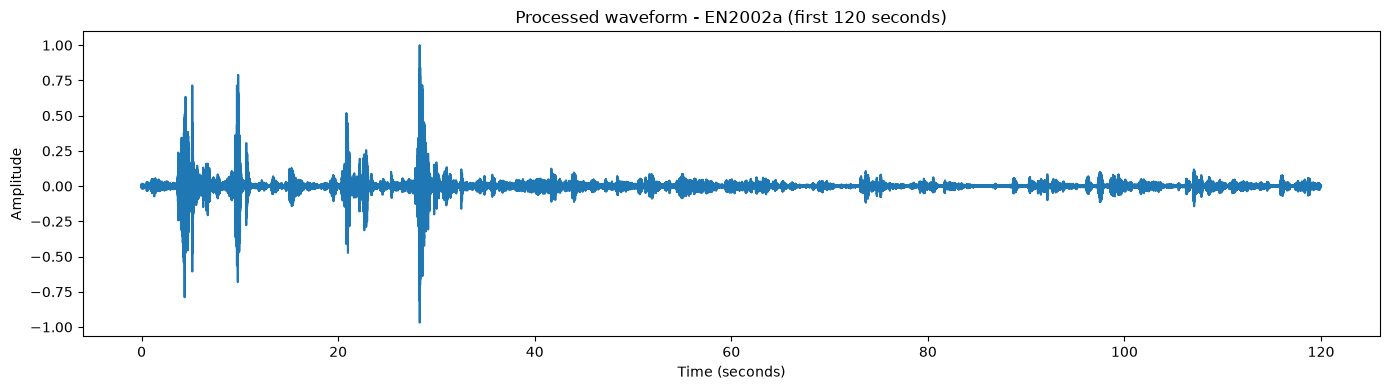

In [46]:
sample_processed = Path(manifest_df.iloc[0]["processed_audio"])
sample_meeting = manifest_df.iloc[0]["meeting_id"]

audio, sr = librosa.load(
    sample_processed,
    sr=None,
    mono=True,
)

plot_duration = min(120, len(audio) / sr)
plot_samples = int(plot_duration * sr)

time_axis = np.arange(plot_samples) / sr

plt.figure(figsize=(14, 4))
plt.plot(time_axis, audio[:plot_samples])
plt.title(
    f"Processed waveform - {sample_meeting} "
    f"(first {plot_duration:.0f} seconds)"
)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

## 17. Final dataset summary

Expected outputs:

- 4 whole-meeting WAV files
- 2 train meetings
- 2 test meetings
- multi-minute audio
- speaker-attributed reference JSON
- readable reference TXT
- processed mono 16 kHz WAV
- `dataset/metadata.csv`

This completes the preprocessing stage and prepares the data for the two STT systems.

In [47]:
print("=" * 70)
print("PREPROCESSING COMPLETE")
print("=" * 70)

print(f"Total meetings    : {len(manifest_df)}")
print(f"Train meetings    : {(manifest_df['split'] == 'train').sum()}")
print(f"Test meetings     : {(manifest_df['split'] == 'test').sum()}")
print(f"Total duration    : {manifest_df['duration_min'].sum():.2f} minutes")
print(f"Metadata manifest : {manifest_path}")

print("\nRaw audio:")
for split in ["train", "test"]:
    files = sorted((RAW_DIR / split).glob("*.wav"))
    print(f"  {split}: {len(files)} file(s)")

print("\nProcessed audio:")
for split in ["train", "test"]:
    files = sorted((PROCESSED_DIR / split).glob("*.wav"))
    print(f"  {split}: {len(files)} file(s)")

print("\nReference JSON:")
for split in ["train", "test"]:
    files = sorted((REFERENCE_DIR / split).glob("*.json"))
    print(f"  {split}: {len(files)} file(s)")

print("\nNext stages:")
print("  1. Whisper STT")
print("  2. AssemblyAI STT")
print("  3. FLAN-T5 T2T")
print("  4. BART T2T")
print("  5. Evaluation")

PREPROCESSING COMPLETE
Total meetings    : 4
Train meetings    : 2
Test meetings     : 2
Total duration    : 92.28 minutes
Metadata manifest : /Users/manish/Documents/KU/SEM 5/DL/DL/dataset/metadata.csv

Raw audio:
  train: 2 file(s)
  test: 2 file(s)

Processed audio:
  train: 2 file(s)
  test: 2 file(s)

Reference JSON:
  train: 2 file(s)
  test: 2 file(s)

Next stages:
  1. Whisper STT
  2. AssemblyAI STT
  3. FLAN-T5 T2T
  4. BART T2T
  5. Evaluation


## Dataset attribution

The AMI meetings used here originate from the AMI Meeting Corpus and are exposed in the `Trelis/tiron-eval-meetings` benchmark dataset.

Keep the dataset attribution in your project report and presentation.